# BRKGA, algoritmos meméticos y Scatter Search

**Bloque 03 · Métodos poblacionales · Notebook 10**

Navegación: [← 09 Algoritmos genéticos](09-algoritmos-geneticos.ipynb) · [11 Enjambre y evolución diferencial →](11-enjambre-pso-evolucion-diferencial.ipynb) · Relacionado: [03 Búsqueda local e ILS](../01-metodos-de-trayectoria/03-busqueda-local-ils.ipynb) · [07 GRASP y path relinking](../02-metodos-con-memoria/07-grasp-path-relinking.ipynb)

## Tabla de contenido
1. Random keys y decodificadores: por qué simplifican el cruce
2. BRKGA: definición, pseudocódigo e implementación desde cero
3. Validación de la implementación
4. BRKGA sobre TSP: parámetros $\rho_e$, $p_e$, $p_m$
5. BRKGA vs. un AG con cruce OX
6. BRKGA sobre QAP
7. Algoritmos meméticos: AG + búsqueda local, Lamarck vs. Baldwin, gestión de diversidad
8. Scatter Search (versión compacta)
9. Comparación global con el mismo trabajo computacional
10. Resumen, ejercicios y referencias

## Qué vas a aprender / Prerrequisitos

**Vas a aprender a**
- representar permutaciones con **claves aleatorias** (*random keys*) y separar el motor evolutivo del problema mediante un **decodificador**;
- implementar BRKGA con cruce sesgado, élite y mutantes, y entender el efecto de $\rho_e$, $p_e$, $p_m$;
- combinar un AG con **búsqueda local** (algoritmo memético) y distinguir la evolución **Lamarckiana** de la **Baldwiniana**;
- gestionar la diversidad de la población con criterios de distancia;
- armar un **Scatter Search** compacto (conjunto de referencia, combinación, mejora);
- comparar métodos con **el mismo trabajo computacional** y varias semillas.

**Prerrequisitos**: [notebook 09](09-algoritmos-geneticos.ipynb) (AG, OX, selección) y 2-opt ([notebook 03](../01-metodos-de-trayectoria/03-busqueda-local-ils.ipynb)).

## 1. Random keys y decodificadores

### Objetivo
Evitar el diseño de operadores de cruce/mutación específicos para cada problema (como OX/PMX/ER en el [notebook 09](09-algoritmos-geneticos.ipynb)) usando un **único motor evolutivo en $[0,1]^n$** y trasladando la especificidad del problema a una función **decodificadora**.

### Intuición
Imagina que a cada ciudad le asignas un número real (su "prioridad"). Ordenas las ciudades por prioridad creciente y obtienes un tour. **Cualquier** vector de claves produce un tour válido, así que cruzar, mutar o interpolar claves **nunca genera soluciones infactibles**. (Bean, 1994, propuso esta idea para secuenciación.)

### Formulación
Sea $\mathbf x\in[0,1]^n$ un cromosoma. El decodificador de permutaciones es
$$\pi=\operatorname{argsort}(\mathbf x):\quad x_{\pi_1}\le x_{\pi_2}\le\dots\le x_{\pi_n}$$
y el valor de aptitud es $f(\mathbf x)=c(\pi)$ con $c$ el costo del problema (longitud del tour, costo QAP, ...). Propiedades:

- **Factibilidad por construcción**: todo $\mathbf x$ con claves distintas decodifica a una permutación; las coincidencias tienen probabilidad cero.
- **Redundancia**: el decodificador es invariante a transformaciones monótonas crecientes de las claves; el espacio $[0,1]^n$ se divide en $n!$ regiones (conos) del mismo volumen, cada una asociada a una permutación.
- **Uniformidad**: si las claves son iid, la permutación decodificada es uniforme sobre $S_n$.
- **Separación de responsabilidades**: el mismo BRKGA sirve para TSP, QAP, scheduling, etc.; solo cambia el decodificador (y puede incluir heurísticas dentro, p. ej. construcción *greedy* guiada por las claves).

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import math, time, multiprocessing as mp
from itertools import combinations

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3, "axes.titlesize": 11})
np.random.seed(0)
rng0 = np.random.default_rng(2024)
CTX = mp.get_context("fork")
def pmap(fn, tasks, procs=10):
    # ejecuta tareas en paralelo (procesos con fork); cada tarea es una tupla pequeña, las funciones se heredan por fork
    with CTX.Pool(min(procs, len(tasks))) as pool:
        return pool.map(fn, tasks, chunksize=1)

# ---------------- Instancias sintéticas (mismos generadores que el notebook 09) ----------------
def make_tsp(n, seed):
    r = np.random.default_rng(seed); xy = r.random((n, 2)) * 100
    return xy, np.linalg.norm(xy[:, None, :] - xy[None, :, :], axis=2)

def tour_len(t, d):
    return d[t, np.roll(t, -1)].sum()

def plot_tour(xy, t, ax, title=""):
    c = np.r_[t, t[0]]; ax.plot(xy[c, 0], xy[c, 1], "-o", ms=4, lw=1.2); ax.set_title(title); ax.set_aspect("equal"); ax.grid(False)

def make_qap(n, seed):
    r = np.random.default_rng(seed)
    F = r.integers(0, 10, (n, n)) * (r.random((n, n)) < 0.5); F = np.triu(F, 1); F = F + F.T
    side = int(np.ceil(np.sqrt(n))); sites = np.array([(i // side, i % side) for i in range(n)])
    return F, np.abs(sites[:, None, :] - sites[None, :, :]).sum(axis=2)

def qap_cost(p, F, D):
    return (F * D[np.ix_(p, p)]).sum()

def succ_pred(t):
    # arreglos sucesor/predecesor de un tour (para comparar aristas en O(n))
    S = np.empty(len(t), int); P = S.copy(); S[t] = np.roll(t, -1); P[t] = np.roll(t, 1); return S, P

def dist_aristas(c, Ss, Ps):
    # distancia de aristas entre el tour c y cada tour dado por sus arreglos (Ss, Ps) -> vector: n - |aristas compartidas|
    cn = np.roll(c, -1); n = len(c)
    return n - ((Ss[:, c] == cn) | (Ps[:, c] == cn)).sum(axis=1)

def es_perm(x, n):
    return len(x) == n and np.array_equal(np.sort(x), np.arange(n))

N_TSP = 40
xy, d = make_tsp(N_TSP, seed=1)          # misma instancia que el notebook 09
print("Referencia: tour aleatorio medio =", np.mean([tour_len(rng0.permutation(N_TSP), d) for _ in range(500)]).round(1))

Referencia: tour aleatorio medio = 2125.4


In [2]:
# ---------------- Decodificadores por lotes (vectorizados) ----------------
def decode_perm(keys):
    # keys: (m, n) -> permutaciones (m, n) ordenando por clave creciente
    return np.argsort(keys, axis=1)

def batch_tsp(keys):
    T = decode_perm(keys)
    return d[T, np.roll(T, -1, axis=1)].sum(axis=1)

# ---- Validación de propiedades del decodificador ----
K = rng0.random((5000, N_TSP))
T = decode_perm(K)
assert all(es_perm(t, N_TSP) for t in T), "decodificación inválida"
print("1) 5000 cromosomas aleatorios -> 5000 permutaciones válidas.")
# invariancia a transformaciones monótonas crecientes
K2 = np.exp(5 * K) ** 3 + 7.0
assert np.array_equal(decode_perm(K), decode_perm(K2))
print("2) El decodificador es invariante a transformaciones monótonas crecientes de las claves.")
# coincide con la longitud recalculada
assert np.allclose(batch_tsp(K[:100]), [tour_len(t, d) for t in T[:100]])
print("3) La aptitud por lotes coincide con la recomputación individual de la longitud.")
# uniformidad: frecuencia de la ciudad que queda en la posición 0
freq = np.bincount(T[:, 0], minlength=N_TSP) / len(T)
print(f"4) Frecuencia de cada ciudad en la posición 0: mín {freq.min():.4f}, máx {freq.max():.4f} (uniforme = {1 / N_TSP:.4f})")

1) 5000 cromosomas aleatorios -> 5000 permutaciones válidas.
2) El decodificador es invariante a transformaciones monótonas crecientes de las claves.
3) La aptitud por lotes coincide con la recomputación individual de la longitud.
4) Frecuencia de cada ciudad en la posición 0: mín 0.0208, máx 0.0308 (uniforme = 0.0250)


## 2. BRKGA

El **Biased Random-Key Genetic Algorithm** (Gonçalves & Resende, 2011) es un AG con una estructura muy específica:

- Población de tamaño $p$, de vectores en $[0,1]^n$.
- Cada generación se ordena por aptitud y se divide en **élite** ($p_e\cdot p$ mejores) y **no élite**.
- La siguiente generación se forma con:
  1. la **élite copiada tal cual** (elitismo; no se reevalúa);
  2. $p_m\cdot p$ **mutantes**: vectores totalmente aleatorios (no hay mutación gen a gen; los mutantes son *inmigrantes*);
  3. el resto ($p-p_ep-p_mp$) por **cruce sesgado**: un padre de la élite y otro de la no élite; cada gen del hijo viene del padre élite con probabilidad $\rho_e>0.5$ y del otro con $1-\rho_e$.

$$ h_i=\begin{cases}x^{\text{élite}}_i&\text{con prob. }\rho_e\\ x^{\text{no élite}}_i&\text{con prob. }1-\rho_e\end{cases}$$

El sesgo $\rho_e$ hace que cada hijo se parezca más al padre élite (explotación) mientras el padre no élite aporta diversidad; los mutantes mantienen la exploración sin parámetros de mutación gen a gen.

### Pseudocódigo
```
P <- p vectores aleatorios en [0,1]^n ; f <- decodificar y evaluar
mientras no se agote el presupuesto:
    ordenar P por f ; E <- primeros pe*p ; N <- resto
    hijos <- para cada uno de (p - pe*p - pm*p):
                 u <- elegir al azar de E ; v <- elegir al azar de N
                 h_i <- u_i con prob. rho_e, si no v_i
    mutantes <- pm*p vectores aleatorios
    evaluar(hijos ∪ mutantes)           # la élite conserva su aptitud
    P <- E ∪ hijos ∪ mutantes
devolver decodificar(mejor)
```
Parámetros recomendados por los autores: $p_e\in[0.10,0.25]$, $p_m\in[0.10,0.30]$, $\rho_e\in[0.5,0.8]$; $p$ proporcional a $n$. Los verificaremos empíricamente.

In [3]:
def brkga_siguiente(pop, f, ne, nm, rho, rng):
    # Una generación de BRKGA. pop,f ya ordenados por f. Devuelve (nueva población parcial: hijos+mutantes) sin élite.
    p, n = pop.shape; nc = p - ne - nm
    elite, noel = pop[:ne], pop[ne:]
    pu = rng.integers(0, ne, nc); pv = rng.integers(0, p - ne, nc)       # un padre élite y uno no élite
    mask = rng.random((nc, n)) < rho                                     # cruce sesgado gen a gen
    hijos = np.where(mask, elite[pu], noel[pv])
    mutantes = rng.random((nm, n))
    return np.vstack([hijos, mutantes])

def brkga(batch_fit, n, p=100, pe=0.2, pm=0.15, rho=0.7, evals=20000, seed=0):
    # BRKGA genérico. batch_fit(keys:(m,n)) -> costos (m,). Minimiza. Devuelve dict con curva (evals, mejor), mejor cromosoma y costo.
    rng = np.random.default_rng(seed)
    ne, nm = int(round(p * pe)), int(round(p * pm))
    pop = rng.random((p, n)); f = batch_fit(pop); usados = p
    o = np.argsort(f); pop, f = pop[o], f[o]
    ev, mejor = [usados], [f[0]]
    while usados < evals:
        nuevos = brkga_siguiente(pop, f, ne, nm, rho, rng)
        fn = batch_fit(nuevos); usados += len(nuevos)            # la élite no se reevalúa
        pop = np.vstack([pop[:ne], nuevos]); f = np.r_[f[:ne], fn]
        o = np.argsort(f); pop, f = pop[o], f[o]
        ev.append(usados); mejor.append(f[0])
    return dict(ev=np.array(ev), best=np.array(mejor), x=pop[0].copy(), f=f[0])

def curva(res, grid):
    return res["best"][np.clip(np.searchsorted(res["ev"], grid, side="right") - 1, 0, None)]

r = brkga(batch_tsp, N_TSP, evals=20000, seed=0)
t_best = decode_perm(r["x"][None])[0]
assert es_perm(t_best, N_TSP) and abs(tour_len(t_best, d) - r["f"]) < 1e-9
print(f"BRKGA (p=100, pe=0.2, pm=0.15, rho=0.7), 20000 evaluaciones -> longitud {r['f']:.1f}")

BRKGA (p=100, pe=0.2, pm=0.15, rho=0.7), 20000 evaluaciones -> longitud 736.9


## 3. Validación de la implementación

Comprobamos tres propiedades que definen al BRKGA:
1. **Monotonía**: el mejor valor nunca empeora (la élite se copia).
2. **Sesgo del cruce**: la fracción de genes que un hijo hereda del padre élite es $\rho_e$. Se verifica con un truco: élite con todos los genes $=0$ y no élite con todos $=1$; entonces la fracción de ceros en los hijos es la fracción heredada de la élite.
3. **Proporciones** de la nueva población: $p_e\,p$ élites, $p_m\,p$ mutantes y el resto hijos.

In [4]:
# 1) monotonía
assert np.all(np.diff(r["best"]) <= 1e-12)
print("1) La curva del mejor es monótona no creciente.")

# 2) sesgo del cruce
rng = np.random.default_rng(0)
p, n, ne, nm = 100, 200, 20, 15
pop_marca = np.vstack([np.zeros((ne, n)), np.ones((p - ne, n))])
for rho in (0.5, 0.7, 0.9):
    nuevos = brkga_siguiente(pop_marca, np.arange(p), ne, nm, rho, rng)
    hijos = nuevos[: p - ne - nm]
    print(f"2) rho={rho}: fracción de genes heredados de la élite = {(hijos == 0).mean():.3f}")

# 3) tamaños
print(f"3) Tamaños: élite {ne}, hijos {p - ne - nm}, mutantes {nm}, total {ne + (p - ne - nm) + nm} = p")

1) La curva del mejor es monótona no creciente.
2) rho=0.5: fracción de genes heredados de la élite = 0.499
2) rho=0.7: fracción de genes heredados de la élite = 0.700
2) rho=0.9: fracción de genes heredados de la élite = 0.901
3) Tamaños: élite 20, hijos 65, mutantes 15, total 100 = p


## 4. BRKGA sobre TSP: efecto de los parámetros

Comparamos cada parámetro variando uno a la vez en torno a $(p,p_e,p_m,\rho_e)=(100,0.2,0.15,0.7)$, con 20 000 evaluaciones y 10 semillas por punto. También hacemos un barrido de $(p_e,p_m)$ en una cuadrícula. Como referencia, un 2-opt multi-arranque encuentra tours de longitud ≈ 465–500 en esta instancia (ver [notebook 09](09-algoritmos-geneticos.ipynb)).

(4s)


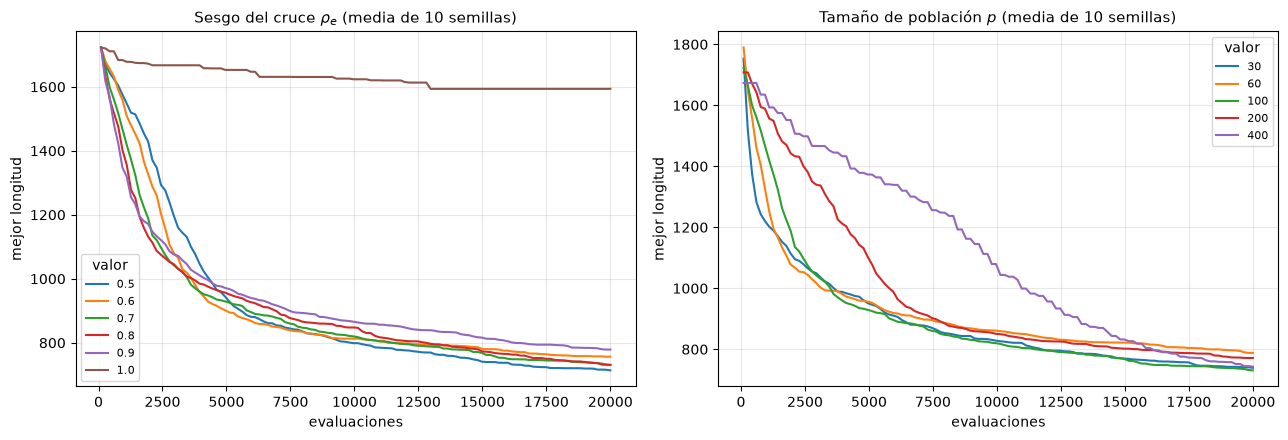

rho_e:
       media  desv.
0.5   713.8   63.7
0.6   756.6   43.3
0.7   727.4   70.6
0.8   730.7   39.8
0.9   778.8   48.6
1.0  1593.6   79.7 

p:
      media  desv.
30   739.1   57.6
60   787.0   43.7
100  727.4   70.6
200  771.0   66.9
400  741.5   45.3


In [5]:
GRID = np.linspace(100, 20000, 120)
def estudio(valores, nombre, **fijos):
    R = {}
    for v in valores:
        kw = dict(fijos); kw[nombre] = v
        R[v] = [brkga(batch_tsp, N_TSP, evals=20000, seed=s, **kw) for s in range(10)]
    return R

t0 = time.time()
R_rho = estudio([0.5, 0.6, 0.7, 0.8, 0.9, 1.0], "rho")
R_pop = estudio([30, 60, 100, 200, 400], "p")
print(f"({time.time()-t0:.0f}s)")
fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, R, tit in [(axs[0], R_rho, r"Sesgo del cruce $\rho_e$"), (axs[1], R_pop, "Tamaño de población $p$")]:
    for v, L in R.items():
        C = np.array([curva(r, GRID) for r in L]); ax.plot(GRID, C.mean(0), label=str(v))
    ax.set_title(tit + " (media de 10 semillas)"); ax.set_xlabel("evaluaciones"); ax.set_ylabel("mejor longitud"); ax.legend(title="valor", fontsize=8)
plt.tight_layout(); plt.show()
fmt = lambda R: pd.DataFrame({v: {"media": np.mean([r["f"] for r in L]), "desv.": np.std([r["f"] for r in L], ddof=1)} for v, L in R.items()}).T.round(1)
print("rho_e:\n", fmt(R_rho), "\n\np:\n", fmt(R_pop))

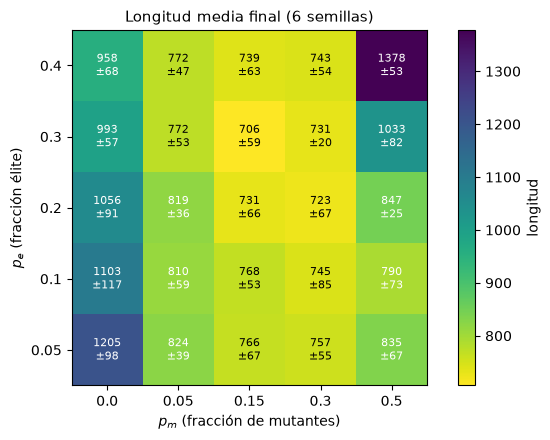

Mejor celda: pe=0.3, pm=0.15  ->  706.0 ± 59.5


In [6]:
# Barrido (pe, pm) con rho=0.7, p=100
PES = [0.05, 0.1, 0.2, 0.3, 0.4]; PMS = [0.0, 0.05, 0.15, 0.3, 0.5]
Z = np.full((len(PES), len(PMS)), np.nan); Zs = Z.copy()
for i, pe in enumerate(PES):
    for j, pm in enumerate(PMS):
        if pe + pm >= 0.95: continue
        v = [brkga(batch_tsp, N_TSP, pe=pe, pm=pm, evals=20000, seed=s)["f"] for s in range(6)]
        Z[i, j], Zs[i, j] = np.mean(v), np.std(v, ddof=1)
fig, ax = plt.subplots(figsize=(6.5, 4.5))
im = ax.imshow(Z, cmap="viridis_r", origin="lower"); ax.grid(False)
ax.set_xticks(range(len(PMS))); ax.set_xticklabels(PMS); ax.set_yticks(range(len(PES))); ax.set_yticklabels(PES)
ax.set_xlabel("$p_m$ (fracción de mutantes)"); ax.set_ylabel("$p_e$ (fracción élite)"); ax.set_title("Longitud media final (6 semillas)")
for i in range(len(PES)):
    for j in range(len(PMS)):
        if not np.isnan(Z[i, j]): ax.text(j, i, f"{Z[i, j]:.0f}\n±{Zs[i, j]:.0f}", ha="center", va="center", color=("k" if Z[i, j] < np.nanmedian(Z) else "w"), fontsize=8)
plt.colorbar(im, label="longitud"); plt.tight_layout(); plt.show()
i, j = np.unravel_index(np.nanargmin(Z), Z.shape); print(f"Mejor celda: pe={PES[i]}, pm={PMS[j]}  ->  {Z[i, j]:.1f} ± {Zs[i, j]:.1f}")

**Lectura (contrastada con las tablas y el mapa impresos arriba).**
- **$\rho_e$**: el caso $\rho_e=1$ es catastrófico: el hijo es copia exacta del padre élite, no hay recombinación y el único aporte de novedad son los mutantes. En el rango $0.5$–$0.8$ las medias son similares y las diferencias quedan dentro de la desviación entre semillas (no hay un mejor $\rho_e$ estadísticamente distinguible); $0.9$ ya empeora algo.
- **Tamaño $p$**: no hay una tendencia monótona clara; con evaluaciones fijas, poblaciones grandes hacen pocas generaciones y poblaciones pequeñas convergen prematuramente, y las diferencias que se ven están dentro del ruido.
- **$(p_e,p_m)$**: la columna $p_m=0$ es la peor: sin inmigrantes ni mutación no hay fuente de variación nueva. La esquina de $p_e$ alta y $p_m=0.5$ también es mala (demasiada aleatoriedad y casi nada de explotación). La región buena es $p_e\approx0.2$–$0.4$ con $p_m\approx0.15$–$0.3$, coherente con los rangos recomendados en la literatura, aunque la celda "mejor" no es distinguible de sus vecinas.

Los rangos de la literatura son un punto de partida, no un óptimo universal: **el mejor ajuste depende de $n$ y del presupuesto**, lo que conecta con el [notebook 15](../05-evaluacion-y-ajuste/15-ajuste-de-parametros.ipynb).

## 5. BRKGA vs. un AG con cruce OX

Para ver el valor de la codificación con claves, comparamos con un AG de permutaciones compacto (generacional con elitismo, torneo $k=5$, OX, mutación por inversión; la mejor configuración encontrada en el [notebook 09](09-algoritmos-geneticos.ipynb)) con **el mismo número de evaluaciones** y 10 semillas. Ojo: el BRKGA está vectorizado, por lo que es además mucho más rápido en tiempo.

(1s)


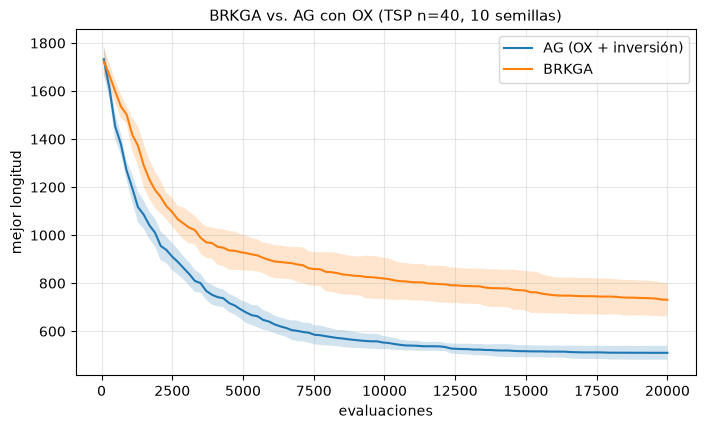

                     media  desv.  mejor
AG (OX + inversión)  510.1   28.9  469.3
BRKGA                727.4   70.6  611.1


In [7]:
# ---------------- AG compacto de permutaciones (OX + inversión + torneo + elitismo) ----------------
def ox_one(p1, p2, rng):
    n = len(p1); a, b = np.sort(rng.choice(n + 1, 2, replace=False))
    child = np.full(n, -1); child[a:b] = p1[a:b]
    used = np.zeros(n, bool); used[p1[a:b]] = True
    rest = np.roll(p2, -b); rest = rest[~used[rest]]
    child[(np.arange(n - (b - a)) + b) % n] = rest
    return child

def mut_inversion(t, rng):
    c = t.copy(); i, j = np.sort(rng.choice(len(t), 2, replace=False)); c[i:j + 1] = c[i:j + 1][::-1]; return c

def ga_ox(d, evals, mu=80, pc=0.9, pm=0.3, k=5, seed=0):
    rng = np.random.default_rng(seed); n = len(d)
    pop = np.argsort(rng.random((mu, n)), axis=1); f = np.array([tour_len(t, d) for t in pop]); ne = mu
    ev, best = [ne], [f.min()]
    while ne < evals:
        cand = rng.integers(0, mu, (mu, k)); pi = cand[np.arange(mu), np.argmin(f[cand], axis=1)]
        kids = []
        for i in range(0, mu, 2):
            a, b = pop[pi[i]], pop[pi[i + 1]]
            if rng.random() < pc: h1, h2 = ox_one(a, b, rng), ox_one(b, a, rng)
            else: h1, h2 = a.copy(), b.copy()
            kids += [mut_inversion(h1, rng) if rng.random() < pm else h1, mut_inversion(h2, rng) if rng.random() < pm else h2]
        kids = np.array(kids); kf = np.array([tour_len(t, d) for t in kids]); ne += mu
        e = np.argmin(f); w = np.argmax(kf)
        kids[w], kf[w] = pop[e], f[e]                       # elitismo 1
        pop, f = kids, kf; ev.append(ne); best.append(f.min())
    i = np.argmin(f)
    return dict(ev=np.array(ev), best=np.array(best), x=pop[i], f=f[i])

t0 = time.time()
def tarea_cmp(task):
    nombre, s = task
    if nombre == "AG (OX + inversión)": return nombre, ga_ox(d, 20000, seed=s)
    return nombre, brkga(batch_tsp, N_TSP, evals=20000, seed=s)
out = pmap(tarea_cmp, [(m, s) for m in ["AG (OX + inversión)", "BRKGA"] for s in range(10)])
R_cmp = {m: [r for (mm, r) in out if mm == m] for m in ["AG (OX + inversión)", "BRKGA"]}
print(f"({time.time()-t0:.0f}s)")
fig, ax = plt.subplots(figsize=(8, 4.5))
for m, L in R_cmp.items():
    C = np.array([curva(r, np.linspace(80, 20000, 100)) for r in L]); mu_, sd = C.mean(0), C.std(0, ddof=1)
    ax.plot(np.linspace(80, 20000, 100), mu_, label=m); ax.fill_between(np.linspace(80, 20000, 100), mu_ - sd, mu_ + sd, alpha=0.2)
ax.set_xlabel("evaluaciones"); ax.set_ylabel("mejor longitud"); ax.set_title("BRKGA vs. AG con OX (TSP n=40, 10 semillas)"); ax.legend(); plt.show()
print(pd.DataFrame({m: {"media": np.mean([r["f"] for r in L]), "desv.": np.std([r["f"] for r in L], ddof=1), "mejor": min(r["f"] for r in L)} for m, L in R_cmp.items()}).T.round(1))
assert all(es_perm(r["x"], N_TSP) for r in R_cmp["AG (OX + inversión)"])

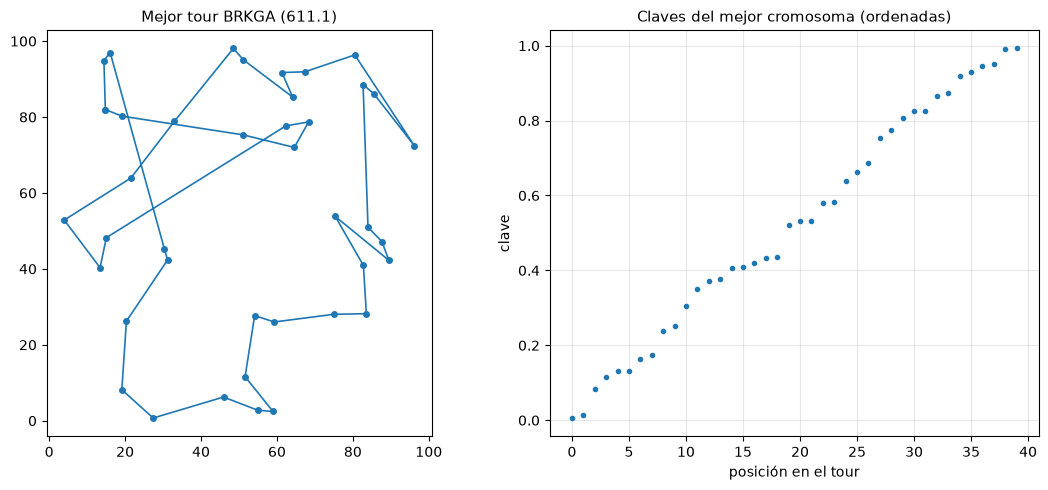

In [8]:
mejor = min(R_cmp["BRKGA"], key=lambda r: r["f"])
fig, axs = plt.subplots(1, 2, figsize=(11, 5))
plot_tour(xy, decode_perm(mejor["x"][None])[0], axs[0], f"Mejor tour BRKGA ({mejor['f']:.1f})")
x = np.sort(mejor["x"]); axs[1].plot(x, "o", ms=3); axs[1].set_title("Claves del mejor cromosoma (ordenadas)")
axs[1].set_xlabel("posición en el tour"); axs[1].set_ylabel("clave"); plt.tight_layout(); plt.show()

**Lectura.** En esta instancia el **AG con OX es claramente mejor** que el BRKGA con decodificador `argsort` (la diferencia de medias es varias veces la desviación estándar). Es un resultado honesto y conocido: el decodificador `argsort` tiene **poca localidad**, porque un cambio pequeño en las claves (o un cruce sesgado que mezcla claves de dos padres) reordena muchas ciudades a la vez, y las adyacencias (lo que importa en el TSP) no se heredan de forma fiable. OX, en cambio, transmite explícitamente tramos de tour. Además BRKGA y el AG con OX son *dos AG distintos* (élite 20% + inmigrantes vs. torneo + OX), no solo "claves vs. permutaciones".

Entonces, ¿para qué sirve BRKGA? Su ventaja principal es de **ingeniería**: un motor único, sin operadores a medida, siempre factible y vectorizable; y su potencia real aparece cuando el **decodificador incorpora conocimiento del problema** (construcción *greedy* guiada por las claves, búsqueda local dentro del decodificador). Con un decodificador ingenuo, puede perder frente a un AG con operadores específicos.

### Test de localidad del decodificador
Medimos cuánto cambia el tour decodificado (en distancia de aristas) cuando se perturban las claves con ruido gaussiano de desviación $\sigma$. Referencia: un movimiento 2-opt modifica exactamente 2 aristas.

In [9]:
Kb = rng0.random((300, N_TSP)); Tb = decode_perm(Kb)
filas = {}
for sg in [0.001, 0.01, 0.03, 0.1, 0.3]:
    Kp = np.clip(Kb + sg * rng0.standard_normal(Kb.shape), 0, 1); Tp = decode_perm(Kp)
    dd = []
    for t1, t2 in zip(Tb, Tp):
        S1, P1 = succ_pred(t1); dd.append(dist_aristas(t2, S1[None], P1[None])[0])
    filas[sg] = {"aristas distintas (media)": np.mean(dd), "fracción de aristas distintas": np.mean(dd) / N_TSP}
print(pd.DataFrame(filas).T.round(3))
print("Referencia: un movimiento 2-opt cambia 2 aristas.")

       aristas distintas (media)  fracción de aristas distintas
0.001                      1.700                          0.042
0.010                     12.813                          0.320
0.030                     23.563                          0.589
0.100                     33.410                          0.835
0.300                     36.807                          0.920
Referencia: un movimiento 2-opt cambia 2 aristas.


Incluso un ruido pequeño ($\sigma=0.01$ con 40 claves en $[0,1]$, es decir, separaciones típicas de $\approx0.025$) cambia varias aristas del tour, y con $\sigma$ moderado el tour decodificado es casi otro tour distinto: el paisaje inducido en el espacio de claves es **muy rugoso** para el TSP. Esto explica por qué el BRKGA con `argsort` rinde peor que un AG con OX y por qué los decodificadores que incorporan heurística (o la búsqueda local) son importantes.

## 6. BRKGA sobre QAP

Para QAP basta **cambiar el decodificador**: la permutación $\pi=\operatorname{argsort}(\mathbf x)$ asigna la instalación $i$ al sitio $\pi_i$ y el costo es $\sum_{ij}F_{ij}D_{\pi_i\pi_j}$. Instancia sintética $n=20$. Comparamos con búsqueda aleatoria y con descenso por intercambios con reinicios (mismo presupuesto de evaluaciones).

In [10]:
Fq, Dq = make_qap(20, seed=4)
def batch_qap(keys):
    P = np.argsort(keys, axis=1)                                 # (m, n)
    M = Dq[P[:, :, None], P[:, None, :]]                         # (m, n, n): D[p_i, p_j]
    return (Fq[None] * M).sum(axis=(1, 2))

# verificación: costo por lotes == costo individual
Kq = rng0.random((50, 20)); Pq = np.argsort(Kq, axis=1)
assert np.allclose(batch_qap(Kq), [qap_cost(p, Fq, Dq) for p in Pq])
print("Costo QAP por lotes verificado contra la recomputación individual.")

def descenso_swaps(p, budget, rng):
    cur = qap_cost(p, Fq, Dq); used = 1; n = len(p); mejora = True
    pares = np.array(list(combinations(range(n), 2)))
    while mejora and used < budget:
        mejora = False
        for i, j in pares[rng.permutation(len(pares))]:
            q = p.copy(); q[i], q[j] = q[j], q[i]; c = qap_cost(q, Fq, Dq); used += 1
            if c < cur: p, cur, mejora = q, c, True; break
            if used >= budget: break
    return p, cur, used

def tarea_qap(task):
    metodo, s = task; EV = 20000; rng = np.random.default_rng(s)
    if metodo.startswith("BRKGA"):
        return metodo, brkga(batch_qap, 20, evals=EV, seed=s, rho=float(metodo.split("=")[1]))["f"]
    if metodo == "aleatoria":
        return metodo, batch_qap(rng.random((EV, 20))).min()
    usados, mejor = 0, np.inf
    while usados < EV:
        p, c, u = descenso_swaps(rng.permutation(20), EV - usados, rng); usados += u; mejor = min(mejor, c)
    return metodo, mejor

t0 = time.time()
metodos = ["aleatoria", "descenso 2-swap con reinicios", "BRKGA rho=0.5", "BRKGA rho=0.7", "BRKGA rho=0.9"]
out = pmap(tarea_qap, [(m, s) for m in metodos for s in range(8)])
tabq = pd.DataFrame({m: {"media": np.mean([v for mm, v in out if mm == m]), "desv.": np.std([v for mm, v in out if mm == m], ddof=1),
                         "mejor": min(v for mm, v in out if mm == m)} for m in metodos}).T.round(1)
print(f"({time.time()-t0:.0f}s)\n", tabq)

Costo QAP por lotes verificado contra la recomputación individual.


(1s)
                                 media  desv.   mejor
aleatoria                      1654.2   20.0  1636.0
descenso 2-swap con reinicios  1347.0   12.6  1332.0
BRKGA rho=0.5                  1502.8   54.5  1412.0
BRKGA rho=0.7                  1525.5   42.3  1484.0
BRKGA rho=0.9                  1552.8   69.9  1464.0


**Lectura.** Mismo motor, otro decodificador (solo cambió `batch_qap`). BRKGA mejora claramente a la búsqueda aleatoria, pero el **descenso por swaps con reinicios es mejor** con el mismo presupuesto y con menos dispersión; entre los tres valores de $\rho_e$ las diferencias quedan dentro de la desviación. Igual que en el [notebook 09](09-algoritmos-geneticos.ipynb), una búsqueda local multi-arranque es un baseline muy duro en QAP pequeño, y un BRKGA "puro" con `argsort` no lo alcanza. La salida natural es **hibridar** con búsqueda local, tema de la siguiente sección.

## 7. Algoritmos meméticos

### Objetivo
Combinar la **exploración global** de un AG con la **explotación local** de una búsqueda local (BL): cada individuo se "educa" con BL antes de ser evaluado/seleccionado. Moscato (1989) los llamó *memético* por analogía con los *memes* de Dawkins (unidades de información cultural que se mejoran por aprendizaje individual).

### Esquema
```
P <- inicializar(mu) ; P <- BL(P)
mientras no se agote el trabajo:
    padres <- seleccion(P) ; hijos <- mutar(cruzar(padres))
    hijos <- BL(hijos)                       # <- el paso memético
    P <- reemplazo(P ∪ hijos)  con control de diversidad
```

### Lamarck vs. Baldwin
Sea $g$ el genotipo del hijo y $\mathrm{BL}(g)$ el resultado de la búsqueda local.
- **Lamarck**: el individuo **reemplaza** su genotipo por $\mathrm{BL}(g)$ (los rasgos adquiridos se heredan). Convergencia rápida; riesgo de colapso de diversidad porque todos los individuos son óptimos locales.
- **Baldwin**: la **aptitud** es $f(\mathrm{BL}(g))$ pero el genotipo sigue siendo $g$. El aprendizaje "suaviza" el paisaje de aptitud (Hinton & Nowlan, 1987; Whitley et al., 1994) y conserva más diversidad genotípica, pero es más lento.

### Costos y diseño
- La BL es **cara**: contar evaluaciones completas subestima el costo. Aquí medimos el **trabajo** en unidades de evaluación de arista (delta de 2-opt = 1 unidad; evaluación completa de tour = $n$ unidades) para comparar justamente.
- **Intensidad** de la BL (descenso completo vs. pocas iteraciones) y **frecuencia** (a todos los hijos o a una fracción) son parámetros de diseño (Krasnogor & Smith, 2005).
- Gestión de **diversidad**: como la BL empuja todo hacia óptimos locales, se descartan hijos demasiado cercanos a individuos ya presentes. Usamos la **distancia de aristas** entre tours, $\delta(\pi,\sigma)=n-|E(\pi)\cap E(\sigma)|$.
- Con BL, una mutación por inversión suele ser *deshecha* por 2-opt; se usa el **doble puente** (*double bridge*), que 2-opt no puede deshacer en un paso.

### Implementación: 2-opt con contador de trabajo

In [11]:
def two_opt_ls(t, d):
    # 2-opt "mejor movimiento por fila i" hasta óptimo local. Devuelve (tour, trabajo) con trabajo = nº de deltas evaluados.
    t = t.copy(); n = len(t); work = 0; mejora = True
    while mejora:
        mejora = False
        for i in range(n - 1):
            js = np.arange(i + 2, n if i > 0 else n - 1)
            if len(js) == 0: continue
            a, b = t[i], t[i + 1]; c, e = t[js], t[(js + 1) % n]
            delta = d[a, c] + d[b, e] - d[a, b] - d[c, e]; work += len(js)
            k = delta.argmin()
            if delta[k] < -1e-9:
                j = js[k]; t[i + 1:j + 1] = t[i + 1:j + 1][::-1]; mejora = True
    return t, work

def mut_double_bridge(t, rng):
    n = len(t); a, b, c = np.sort(rng.choice(np.arange(1, n), 3, replace=False))
    return np.r_[t[:a], t[b:c], t[a:b], t[c:]]

# ---- Verificación de la búsqueda local ----
rng = np.random.default_rng(1); ok = 0
for _ in range(20):
    t0_ = rng.permutation(N_TSP); t1, w = two_opt_ls(t0_, d)
    assert es_perm(t1, N_TSP) and tour_len(t1, d) <= tour_len(t0_, d) + 1e-9
    # óptimo local: ninguna inversión (i,j) mejora el tour (comprobación por fuerza bruta con recomputación completa)
    L = tour_len(t1, d)
    for i in range(N_TSP - 1):
        for j in range(i + 2, N_TSP if i > 0 else N_TSP - 1):
            t2 = t1.copy(); t2[i + 1:j + 1] = t2[i + 1:j + 1][::-1]
            assert tour_len(t2, d) >= L - 1e-9
    ok += 1
print(f"2-opt verificado en {ok} arranques: salida es permutación, no empeora, y es óptimo local respecto a todos los movimientos 2-opt.")
S_, P_ = succ_pred(np.arange(N_TSP)); a_, b_ = rng.permutation(N_TSP), np.arange(N_TSP)
assert dist_aristas(a_, *map(lambda z: z[None], (S_, P_)))[0] == N_TSP - len(set(frozenset((int(a_[i]), int(a_[(i+1) % N_TSP]))) for i in range(N_TSP)) & set(frozenset((i, (i+1) % N_TSP)) for i in range(N_TSP)))
print("Distancia de aristas verificada contra el cálculo con conjuntos.")
ws = [two_opt_ls(rng.permutation(N_TSP), d)[1] for _ in range(20)]
print(f"Trabajo de un 2-opt desde un tour aleatorio: media {np.mean(ws):.0f} unidades (una evaluación completa = {N_TSP}).")

2-opt verificado en 20 arranques: salida es permutación, no empeora, y es óptimo local respecto a todos los movimientos 2-opt.
Distancia de aristas verificada contra el cálculo con conjuntos.
Trabajo de un 2-opt desde un tour aleatorio: media 4255 unidades (una evaluación completa = 40).


In [12]:
# ---------------- Algoritmo memético (mu+lambda) con BL 2-opt, modos Lamarck / Baldwin, con o sin control de diversidad ----------------
def memetico(d, modo, work_budget, mu=20, lam=20, dedup=True, theta=2, k=3, pm=0.5, seed=0):
    rng = np.random.default_rng(seed); n = len(d); work = 0
    def educar(g):
        nonlocal work
        t2, w = two_opt_ls(g, d); work += w + n
        return (t2 if modo == "lamarck" else g), tour_len(t2, d), t2           # (genotipo, aptitud, tour BL)
    pop, f, tours = [], [], []
    for _ in range(mu):
        g, fi, t2 = educar(rng.permutation(n)); pop.append(g); f.append(fi); tours.append(t2)
    pop, f, tours = np.array(pop), np.array(f), np.array(tours)
    ib = f.argmin(); best_f, best_t = f[ib], tours[ib].copy()
    trace = [(work, best_f)]; divs = []
    def diversidad(P):
        Ss, Ps = zip(*[succ_pred(t) for t in P]); Ss, Ps = np.array(Ss), np.array(Ps)
        return np.mean([dist_aristas(P[i], Ss[i + 1:], Ps[i + 1:]).mean() for i in range(len(P) - 1)]) / n
    divs.append(diversidad(pop))
    while work < work_budget:
        cand = rng.integers(0, len(pop), (lam, k)); pi = cand[np.arange(lam), np.argmin(f[cand], axis=1)]
        kids, kf, kt = [], [], []
        for i in range(0, lam, 2):
            a, b = pop[pi[i]], pop[pi[(i + 1) % lam]]
            for h in (ox_one(a, b, rng), ox_one(b, a, rng)):
                if rng.random() < pm: h = mut_double_bridge(h, rng)
                g, fi, t2 = educar(h); kids.append(g); kf.append(fi); kt.append(t2)
                if fi < best_f: best_f, best_t = fi, t2.copy()
        allp = np.vstack([pop, kids]); allf = np.r_[f, kf]; allt = np.vstack([tours, kt])
        order = np.argsort(allf); keep = []
        if dedup:                                           # filtro de diversidad: se rechazan tours a distancia <= theta de uno ya aceptado
            Ss = np.empty((0, n), int); Ps = Ss.copy()
            for idx in order:
                if len(keep) == mu: break
                if len(keep) == 0 or dist_aristas(allp[idx], Ss, Ps).min() > theta:
                    keep.append(idx); s_, p_ = succ_pred(allp[idx]); Ss = np.vstack([Ss, s_]); Ps = np.vstack([Ps, p_])
            for idx in order:                               # si faltan, se completa con los mejores restantes
                if len(keep) == mu: break
                if idx not in keep: keep.append(idx)
        else:
            keep = list(order[:mu])
        pop, f, tours = allp[keep], allf[keep], allt[keep]
        trace.append((work, best_f)); divs.append(diversidad(pop))
    return dict(trace=np.array(trace), div=np.array(divs), f=best_f, x=best_t, work=work)

res = memetico(d, "lamarck", 600_000, seed=0)
assert es_perm(res["x"], N_TSP) and abs(tour_len(res["x"], d) - res["f"]) < 1e-9
print(f"Memético (Lamarck, dedup): mejor {res['f']:.1f} con {res['work']:,} unidades de trabajo, {len(res['trace']) - 1} generaciones.")

Memético (Lamarck, dedup): mejor 465.1 con 651,860 unidades de trabajo, 10 generaciones.


(10s)


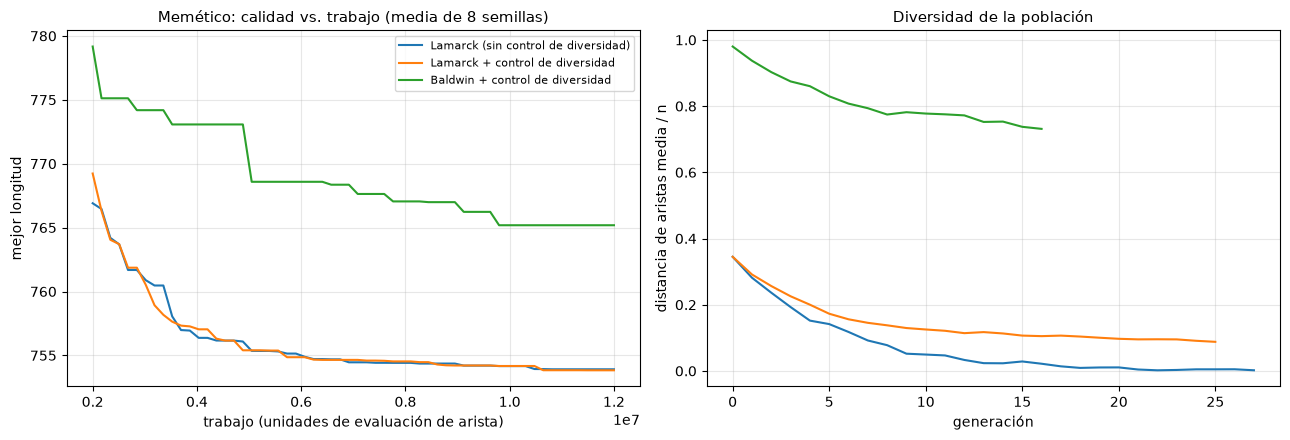

                                       media  desv.    mejor  \
Lamarck (sin control de diversidad)  753.914  1.478  753.367   
Lamarck + control de diversidad      753.834  1.272  753.367   
Baldwin + control de diversidad      764.937  3.252  761.144   

                                     generaciones (media)  diversidad final  
Lamarck (sin control de diversidad)                31.250             0.001  
Lamarck + control de diversidad                    26.750             0.088  
Baldwin + control de diversidad                    16.625             0.718  


In [13]:
# Para las secciones 7-9 usamos una instancia MAYOR (n=100): con n=40 todos los métodos con BL llegan al mismo tour (probablemente óptimo)
N2 = 100
xy2, d2 = make_tsp(N2, seed=11)
WORK = 12_000_000
CFG_MEM = {"Lamarck (sin control de diversidad)": dict(modo="lamarck", dedup=False),
           "Lamarck + control de diversidad": dict(modo="lamarck", dedup=True),
           "Baldwin + control de diversidad": dict(modo="baldwin", dedup=True)}
def tarea_mem(task):
    nombre, s = task
    return nombre, memetico(d2, work_budget=WORK, seed=s, **CFG_MEM[nombre])

t0 = time.time()
out = pmap(tarea_mem, [(k, s) for k in CFG_MEM for s in range(8)])
R_mem = {k: [r for (kk, r) in out if kk == k] for k in CFG_MEM}
print(f"({time.time()-t0:.0f}s)")
GW = np.linspace(2e6, WORK, 60)
def en_trabajo(res, g):
    w, b = res["trace"][:, 0], res["trace"][:, 1]
    idx = np.searchsorted(w, g, side="right") - 1
    return np.where(idx >= 0, b[np.clip(idx, 0, None)], np.nan)
fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))
for k, L in R_mem.items():
    C = np.array([en_trabajo(r, GW) for r in L]); axs[0].plot(GW, np.nanmean(C, 0), label=k)
    nmin = min(len(r["div"]) for r in L); axs[1].plot(np.mean([r["div"][:nmin] for r in L], axis=0), label=k)
axs[0].set_xlabel("trabajo (unidades de evaluación de arista)"); axs[0].set_ylabel("mejor longitud"); axs[0].set_title("Memético: calidad vs. trabajo (media de 8 semillas)")
axs[1].set_xlabel("generación"); axs[1].set_ylabel("distancia de aristas media / n"); axs[1].set_title("Diversidad de la población")
axs[0].legend(fontsize=8); plt.tight_layout(); plt.show()
print(pd.DataFrame({k: {"media": np.mean([r["f"] for r in L]), "desv.": np.std([r["f"] for r in L], ddof=1), "mejor": min(r["f"] for r in L),
                         "generaciones (media)": np.mean([len(r["trace"]) - 1 for r in L]),
                         "diversidad final": np.mean([r["div"][-1] for r in L])} for k, L in R_mem.items()}).T.round(3))

**Lectura (instancia $n=100$, contrastada con la tabla y las curvas).**
- **Diversidad** (derecha): en Lamarck *sin* control la población colapsa a prácticamente un solo tour (diversidad ≈ 0): todos son el mismo óptimo local y el cruce deja de aportar. El **filtro de distancia** mantiene una diversidad pequeña pero positiva. En **Baldwin** el genotipo no se "educa" y la diversidad genotípica se mantiene muy alta.
- **Calidad por trabajo**: Lamarck con y sin control de diversidad terminan prácticamente iguales (diferencia mucho menor que la desviación): con este presupuesto el colapso aún no cuesta calidad, aunque lo haría con presupuestos mayores. **Baldwin es claramente peor** por el mismo trabajo y hace menos generaciones: sus hijos no descienden de óptimos locales, así que cada 2-opt es más caro, y la selección "ve" aptitudes mejoradas pero el genotipo no acumula ese progreso. Es un resultado dependiente del problema (la literatura reporta casos favorables a Baldwin, sobre todo en paisajes engañosos).
- El número de generaciones del memético es **pequeño** (decenas): el costo de la BL domina; por eso se mide el trabajo y no las "generaciones".

## 8. Scatter Search (versión compacta)

**Scatter Search** (Glover, 1977; Laguna & Martí, 2003) es un método poblacional **determinista y con población pequeña**: en lugar de muchos individuos y azar, mantiene un **conjunto de referencia** (*RefSet*) de pocas soluciones buenas y *dispersas* y las combina sistemáticamente. Plantilla de cinco métodos:

1. **Generación de diversificación**: produce un conjunto amplio $P$ de soluciones diversas (aquí aleatorias + BL).
2. **Mejora**: BL (2-opt).
3. **Actualización del RefSet**: $b_1$ soluciones de **calidad** + $b_2$ soluciones de **diversidad** (las que maximizan la distancia mínima al RefSet).
4. **Generación de subconjuntos**: aquí todos los **pares** con al menos un miembro nuevo.
5. **Combinación**: aquí OX en ambos sentidos (2 hijos por par; alternativa clásica: *path relinking*, ver [notebook 07](../02-metodos-con-memoria/07-grasp-path-relinking.ipynb)) seguida de mejora.

Cuando el RefSet no cambia, se **reconstruye** conservando las mejores soluciones y generando nuevas diversas. Complejidad por iteración: $O(b^2)$ combinaciones ($b=b_1+b_2$), cada una con una BL.

In [14]:
def scatter_search(d, work_budget, P=20, b1=4, b2=4, seed=0):
    rng = np.random.default_rng(seed); n = len(d); work = 0
    def mejorar(t):
        nonlocal work
        t2, w = two_opt_ls(t, d); work += w + n; return t2
    def clave(t): return t.tobytes()
    def construir_refset(cands, fcands, ref_prev=None):
        # b1 por calidad + b2 por diversidad (max-min distancia de aristas al RefSet actual)
        order = np.argsort(fcands); sel = []
        Ss = np.empty((0, n), int); Ps = Ss.copy()
        for i in order:                                              # calidad (distintos entre sí)
            if len(sel) == b1: break
            if len(sel) == 0 or dist_aristas(cands[i], Ss, Ps).min() > 0:
                sel.append(i); s_, p_ = succ_pred(cands[i]); Ss = np.vstack([Ss, s_]); Ps = np.vstack([Ps, p_])
        resto = [i for i in range(len(cands)) if i not in sel]
        while len(sel) < b1 + b2 and resto:                          # diversidad
            Ss, Ps = map(np.array, zip(*[succ_pred(cands[j]) for j in sel]))
            dm = [dist_aristas(cands[i], Ss, Ps).min() for i in resto]
            sel.append(resto.pop(int(np.argmax(dm))))
        return sel
    # 1-2) diversificación + mejora
    pool = [mejorar(rng.permutation(n)) for _ in range(P)]
    fpool = np.array([tour_len(t, d) for t in pool]); pool = np.array(pool)
    sel = construir_refset(pool, fpool); ref = pool[sel]; fref = fpool[sel]; nuevo = np.ones(len(ref), bool)
    best_f = fref.min(); best_t = ref[fref.argmin()].copy(); trace = [(work, best_f)]; reinicios = 0
    while work < work_budget:
        pares = [(i, j) for i in range(len(ref)) for j in range(i + 1, len(ref)) if nuevo[i] or nuevo[j]]
        if not pares:                                                # RefSet estable -> reconstrucción
            reinicios += 1
            pool = [mejorar(rng.permutation(n)) for _ in range(P)]
            if work >= work_budget: break
            fpool = np.array([tour_len(t, d) for t in pool]); allc = np.vstack([ref[np.argsort(fref)[:b1]], pool]); allf = np.r_[np.sort(fref)[:b1], fpool]
            sel = construir_refset(allc, allf); ref, fref = allc[sel], allf[sel]; nuevo = np.ones(len(ref), bool); continue
        kids, kf = [], []
        for i, j in pares:
            for h in (ox_one(ref[i], ref[j], rng), ox_one(ref[j], ref[i], rng)):
                h = mejorar(h); kids.append(h); kf.append(tour_len(h, d))
                if kf[-1] < best_f: best_f, best_t = kf[-1], h.copy()
            if work >= work_budget: break
        viejos = {clave(t) for t in ref}
        allc = np.vstack([ref, kids]); allf = np.r_[fref, kf]
        uniq = {};
        for t, fv in zip(allc, allf): uniq.setdefault(clave(t), (t, fv))                # sin duplicados exactos
        allc = np.array([v[0] for v in uniq.values()]); allf = np.array([v[1] for v in uniq.values()])
        sel = construir_refset(allc, allf); ref, fref = allc[sel], allf[sel]
        nuevo = np.array([clave(t) not in viejos for t in ref])
        trace.append((work, best_f))
    return dict(trace=np.array(trace), f=best_f, x=best_t, work=work, reinicios=reinicios)

r = scatter_search(d, 800_000, seed=0)
assert es_perm(r["x"], N_TSP) and abs(tour_len(r["x"], d) - r["f"]) < 1e-9      # prueba rápida en la instancia n=40
print(f"Scatter Search: mejor {r['f']:.1f}, trabajo {r['work']:,}, reconstrucciones del RefSet: {r['reinicios']}")

Scatter Search: mejor 465.1, trabajo 851,920, reconstrucciones del RefSet: 1


## 9. Comparación global con el mismo trabajo computacional

Para estas comparaciones usamos una instancia mayor, $n=100$ (con $n=40$ todos los métodos con búsqueda local alcanzan el mismo tour, así que no discriminan). Todos los métodos reciben el mismo **presupuesto de trabajo** $W=1.2\times10^7$ unidades (una evaluación completa de tour cuenta $n=100$; un delta de 2-opt cuenta 1). Así, los métodos sin BL (AG, BRKGA) pueden hacer $W/n=120\,000$ evaluaciones, mientras que los que usan 2-opt gastan su presupuesto en búsqueda local. Incluimos como referencia el **2-opt multi-arranque** (reiniciar desde tours aleatorios hasta agotar $W$). Ocho semillas por método.

(16s)
Todas las soluciones finales son permutaciones válidas con longitud verificada.
                         media  desv.    mejor     peor  % sobre mejor global
AG (OX)                 829.09  14.51   799.25   841.62                 10.05
BRKGA                  1568.03  41.73  1492.68  1619.60                108.14
Memético Lamarck+div.   753.83   1.27   753.37   756.98                  0.06
Memético Baldwin+div.   764.94   3.25   761.14   770.75                  1.54
Scatter Search          755.58   1.80   753.37   757.17                  0.29
2-opt multi-arranque    766.77   4.87   758.17   772.58                  1.78
Mejor longitud global observada: 753.37


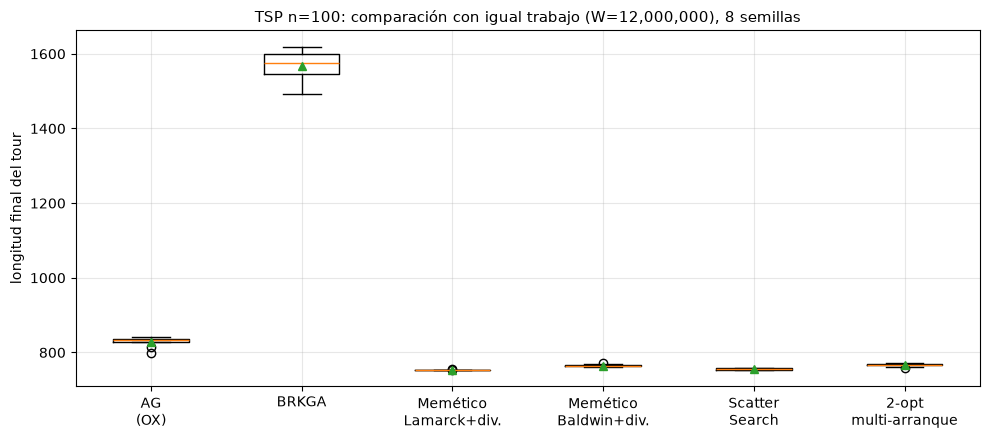

In [15]:
def batch2(keys):
    T = decode_perm(keys); return d2[T, np.roll(T, -1, axis=1)].sum(axis=1)

def multistart_2opt(d, work_budget, seed=0):
    rng = np.random.default_rng(seed); n = len(d); work = 0; best = np.inf; bt = None
    while work < work_budget:
        t, w = two_opt_ls(rng.permutation(n), d); work += w + n
        if tour_len(t, d) < best: best, bt = tour_len(t, d), t
    return dict(f=best, x=bt)

def tarea_global(task):
    m, s = task; ev = WORK // N2
    if m == "AG (OX)":                   return m, ga_ox(d2, ev, mu=100, seed=s)
    if m == "BRKGA":                     return m, brkga(batch2, N2, p=200, evals=ev, seed=s)
    if m == "Memético Lamarck+div.":     return m, memetico(d2, "lamarck", WORK, seed=s)
    if m == "Memético Baldwin+div.":     return m, memetico(d2, "baldwin", WORK, seed=s)
    if m == "Scatter Search":            return m, scatter_search(d2, WORK, seed=s)
    return m, multistart_2opt(d2, WORK, seed=s)
METODOS = ["AG (OX)", "BRKGA", "Memético Lamarck+div.", "Memético Baldwin+div.", "Scatter Search", "2-opt multi-arranque"]
t0 = time.time()
out = pmap(tarea_global, [(m, s) for m in METODOS for s in range(8)])
G = {m: [r for (mm, r) in out if mm == m] for m in METODOS}
print(f"({time.time()-t0:.0f}s)")
for m, L in G.items():
    for r in L:
        x = r["x"] if r["x"].ndim == 1 and r["x"].dtype.kind == "i" else decode_perm(r["x"][None])[0]
        assert es_perm(x, N2) and abs(tour_len(x, d2) - r["f"]) < 1e-6, m
print("Todas las soluciones finales son permutaciones válidas con longitud verificada.")
mejor_global = min(r["f"] for L in G.values() for r in L)
tab = pd.DataFrame({m: {"media": np.mean([r["f"] for r in L]), "desv.": np.std([r["f"] for r in L], ddof=1), "mejor": min(r["f"] for r in L),
                        "peor": max(r["f"] for r in L)} for m, L in G.items()}).T
tab["% sobre mejor global"] = 100 * (tab["media"] / mejor_global - 1)
print(tab.round(2)); print("Mejor longitud global observada:", round(mejor_global, 2))
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.boxplot([[r["f"] for r in L] for L in G.values()], showmeans=True)
ax.set_xticks(range(1, len(G) + 1)); ax.set_xticklabels([m.replace(" ", "\n", 1) for m in G])
ax.set_ylabel("longitud final del tour"); ax.set_title(f"TSP n=100: comparación con igual trabajo (W={WORK:,}), 8 semillas"); plt.tight_layout(); plt.show()

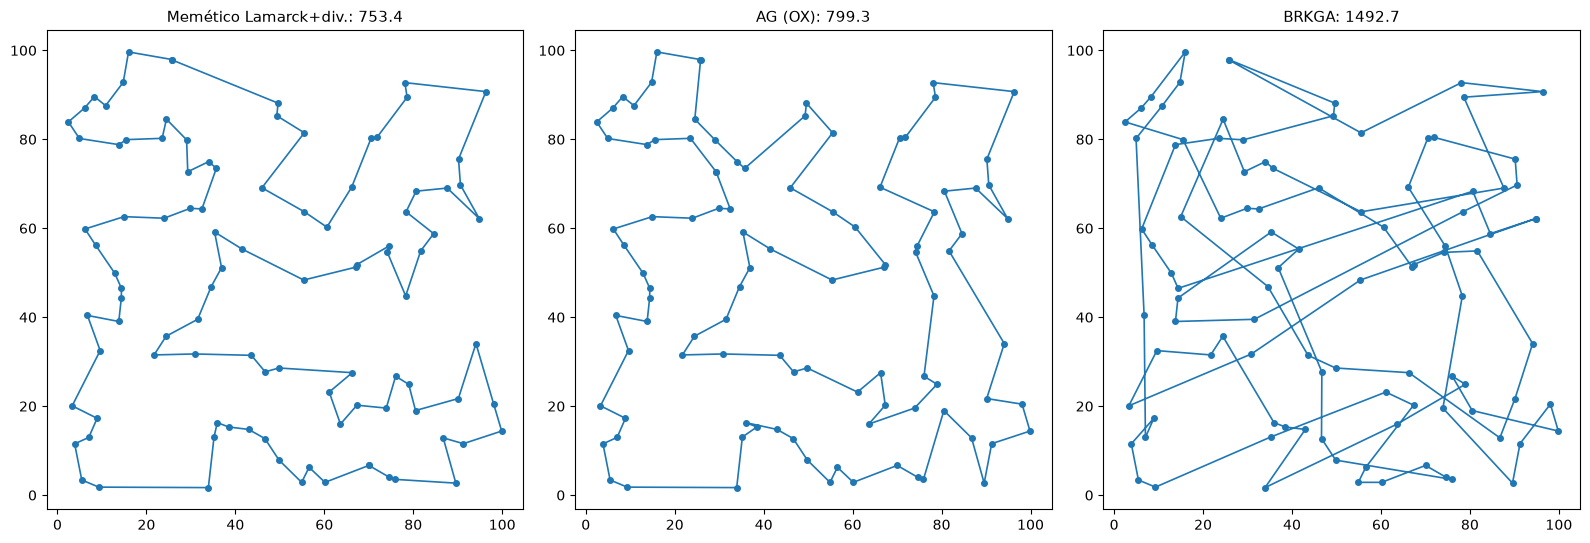

In [16]:
# Mejor tour encontrado por tres métodos (instancia n=100)
def a_tour(r): return r["x"] if r["x"].dtype.kind == "i" else decode_perm(r["x"][None])[0]
fig, axs = plt.subplots(1, 3, figsize=(16, 5.2))
for ax, m in zip(axs, ["Memético Lamarck+div.", "AG (OX)", "BRKGA"]):
    r = min(G[m], key=lambda r: r["f"]); plot_tour(xy2, a_tour(r), ax, f"{m}: {r['f']:.1f}")
plt.tight_layout(); plt.show()

**Lectura (contrastada con la tabla).** Con el mismo trabajo en esta instancia: (i) el memético Lamarckiano y el Scatter Search, ambos **poblacionales + búsqueda local**, quedan a la cabeza, con diferencias entre sí menores que la desviación entre semillas (no concluyentes); (ii) ambos superan al **2-opt multi-arranque**, que a su vez es mejor que el AG "puro" con OX: la BL explota la estructura métrica del TSP, y combinarla con recombinación aporta algo más que reiniciar; (iii) el memético Baldwin queda cerca del multi-arranque; (iv) el **BRKGA con `argsort` queda muy atrás** del resto, coherente con la baja localidad del decodificador discutida antes (con presupuestos mayores mejora, pero no alcanza a los híbridos). Con 8 semillas y una sola instancia **no se puede declarar un ganador universal**; un diseño riguroso usaría varias instancias y pruebas estadísticas (tema del [notebook 14](../05-evaluacion-y-ajuste/14-medicion-de-desempeno.ipynb)).

## Ventajas y limitaciones

| Método | Ventajas | Limitaciones |
|---|---|---|
| **BRKGA** | motor único; factibilidad por construcción; pocos parámetros; paralelizable; decodificador intercambiable | redundancia del decodificador (muchas claves ↔ una permutación); sin BL puede quedar lejos de métodos específicos; el decodificador concentra el conocimiento del problema |
| **Memético** | combina exploración y explotación; suele dar la mejor calidad por trabajo | la BL domina el costo; riesgo de convergencia prematura (óptimos locales parecidos); más decisiones de diseño (Lamarck/Baldwin, intensidad) |
| **Scatter Search** | población pequeña; determinista y sistemático; fuerte con buena combinación y mejora | requiere diseñar diversificación, combinación y actualización del RefSet; más ingeniería que un AG simple |

## Resumen
- **Random keys + decodificador** desacoplan el motor evolutivo del problema; toda clave produce una solución factible.
- **BRKGA** = élite copiada + mutantes inmigrantes + cruce sesgado $\rho_e$; verificamos sus proporciones y su sesgo de herencia.
- Los **meméticos** insertan BL en el AG; Lamarck acelera, Baldwin conserva diversidad; el **filtro de diversidad por distancia de aristas** previene el colapso.
- **Scatter Search** mantiene un RefSet (calidad + dispersión) y combina todos los pares.
- Siempre compara con **trabajo igual** y con baselines fuertes; reporta media $\pm$ desviación.

## Ejercicios propuestos
1. Modifica el decodificador de BRKGA para que **construya el tour con *nearest neighbor* guiado por las claves** (las claves ordenan la prioridad de arranque o perturban distancias) y compara con `argsort`.
2. Implementa BRKGA **multi-población** con migración de élites y mide el efecto en la diversidad.
3. Aplica BRKGA + 2-opt solo a la **élite** cada $g$ generaciones (intensidad parcial de la BL) y compara con el memético puro.
4. Implementa BL probabilística: aplicar 2-opt a cada hijo con prob. $p_{ls}\in\{0.1,0.3,1\}$ y estudia el balance calidad/trabajo.
5. Sustituye el OX del Scatter Search por **path relinking** ([notebook 07](../02-metodos-con-memoria/07-grasp-path-relinking.ipynb)).
6. Escribe un memético para el QAP con BL de 2-swap y compara con la búsqueda tabú ([notebook 06](../02-metodos-con-memoria/06-busqueda-tabu.ipynb)).

## Referencias
- Bean, J. C. (1994). Genetic algorithms and random keys for sequencing and optimization. *ORSA Journal on Computing*, 6(2).
- Gonçalves, J. F., Resende, M. G. C. (2011). Biased random-key genetic algorithms for combinatorial optimization. *Journal of Heuristics*, 17(5).
- Moscato, P. (1989). On evolution, search, optimization, genetic algorithms and martial arts: towards memetic algorithms. *Caltech Concurrent Computation Program, Report 826*.
- Krasnogor, N., Smith, J. (2005). A tutorial for competent memetic algorithms: model, taxonomy, and design issues. *IEEE Transactions on Evolutionary Computation*, 9(5).
- Hinton, G. E., Nowlan, S. J. (1987). How learning can guide evolution. *Complex Systems*, 1.
- Whitley, D., Gordon, V. S., Mathias, K. (1994). Lamarckian evolution, the Baldwin effect and function optimization. *Parallel Problem Solving from Nature (PPSN III)*.
- Glover, F. (1977). Heuristics for integer programming using surrogate constraints. *Decision Sciences*, 8(1).
- Laguna, M., Martí, R. (2003). *Scatter Search: Methodology and Implementations in C*. Kluwer.
- Eiben, A. E., Smith, J. E. (2003). *Introduction to Evolutionary Computing*. Springer.